# A-B04 epoch 290 — 큰 오탐 검토

정답과 한 voxel도 겹치지 않는 **26-connectivity 예측 component 중 1,001 voxel 이상**을 검토합니다. 정답 기준 오탐이며, 라벨 누락 여부는 영상 검토 후 판단합니다. 작은 component를 지우거나 원본 라벨을 수정하지 않습니다.

위에서부터 실행하세요. `model/.venv` 커널의 numpy, pandas, scipy, nibabel, matplotlib만 사용합니다. 전체 46건을 다시 읽어 후보를 계산하므로 첫 집계에는 시간이 걸립니다.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import nibabel as nib
from nibabel.processing import resample_from_to
from scipy import ndimage
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets").is_dir() and (p / "model").is_dir())
FOLD = ROOT / "model/runs/aneurysm_binary/nnunet/Dataset503_TopAneuMRABinary/nnUNetTrainerAneurysmBinaryBaseline__AneurysmBinaryPlansTverskyFocalV1__3d_fullres/fold_0"
PRED_DIR = FOLD / "full_validation/epoch_0290"
RAW = ROOT / "datasets/aneurysm/v2/model_ready/nnunet/nnUNet_raw/Dataset503_TopAneuMRABinary/imagesTr"
OUT = ROOT / "model/runs/aneurysm_binary/A-B04/fp_review_epoch_0290"
OUT.mkdir(parents=True, exist_ok=True)
REVIEW_PATH = OUT / "manual_review.csv"
summary = json.loads((PRED_DIR / "summary.json").read_text())
CASES = {Path(r["prediction_file"]).name.removesuffix(".nii.gz"): r for r in summary["metric_per_case"]}
STRUCTURE = ndimage.generate_binary_structure(3, 3)


In [2]:
records = []
for case_id, r in CASES.items():
    gt_img = nib.load(r["reference_file"])
    pred_img = nib.load(PRED_DIR / f"{case_id}.nii.gz")
    assert gt_img.shape == pred_img.shape and np.allclose(gt_img.affine, pred_img.affine, atol=1e-5), case_id
    gt = np.asanyarray(gt_img.dataobj) > 0
    labels, n = ndimage.label(np.asanyarray(pred_img.dataobj) > 0, STRUCTURE)
    counts = np.bincount(labels.ravel())
    overlaps = set(np.unique(labels[gt]))
    voxel_ml = abs(np.linalg.det(pred_img.affine[:3, :3])) / 1000
    for component in range(1, n + 1):
        if component not in overlaps:
            records.append(dict(case_id=case_id, component=component,
                                voxels=int(counts[component]), volume_ml=float(counts[component]*voxel_ml)))
    del gt, labels
all_fp = pd.DataFrame(records).sort_values("voxels", ascending=False).reset_index(drop=True)
candidates = all_fp.loc[all_fp.voxels >= 1001].reset_index(drop=True).copy()
candidates.index.name = "candidate"
all_fp.to_csv(OUT / "all_fp_components.csv", index=False)
candidates.to_csv(OUT / "large_fp_candidates.csv")
print(f"전체 FP: {len(all_fp)} / large FP: {len(candidates)} / total FP component voxels: {all_fp.voxels.sum():,}")
display(candidates)


전체 FP: 60 / large FP: 8 / total FP component voxels: 24,224


,case_id,component,voxels,volume_ml
candidate,,,,
0,topaneu_center5_mr_462,2,5981,0.245396
1,topaneu_center5_mr_011,2,3020,0.311050
2,topaneu_center1_mr_770,3,2651,0.174378
3,topaneu_center2_mr_077,1,2193,0.106837
4,topaneu_center2_mr_080,2,1365,0.066499
5,topaneu_center1_mr_386,1,1254,0.082336
6,topaneu_center1_mr_664,3,1125,0.073850
7,topaneu_center5_mr_063,4,1094,0.048622


## 영상 확인

`show_candidate(0)`처럼 표의 candidate 번호를 지정합니다. 각 행은 정규화한 RAS voxel grid의 X/Y/Z 단면입니다. 축은 voxel 좌표이며 사선 촬영에서는 정확한 해부학적 정중면과 다를 수 있습니다.

열: **원본 MRA → 원본+GT(초록) → 원본+GT+전체 예측(빨강)+검토 대상(노랑)**. 원본은 예측 grid로 선형 보간하고 마스크는 최근접 보간합니다. 판정 전 여러 단면에서 연속성을 확인하세요.


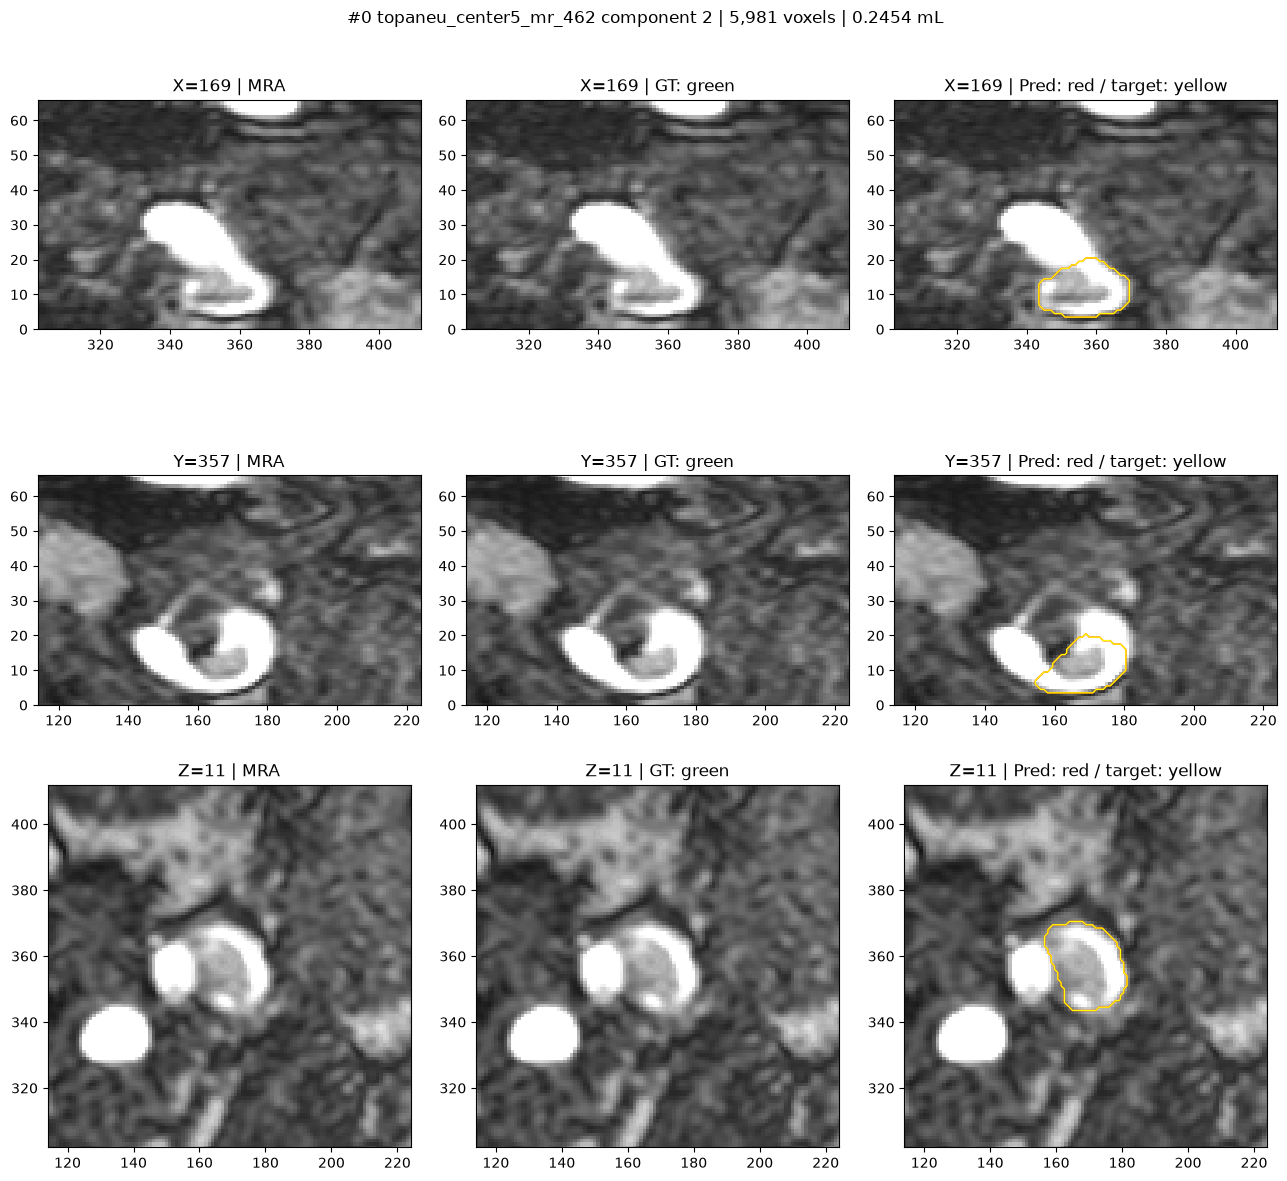

In [3]:
_cache = {}
def load_candidate(index):
    row = candidates.loc[index]
    key = (row.case_id, int(row.component))
    if _cache.get("key") == key:
        return _cache["data"]
    pred_img = nib.load(PRED_DIR / f"{row.case_id}.nii.gz")
    labels, _ = ndimage.label(np.asanyarray(pred_img.dataobj) > 0, STRUCTURE)
    component_img = nib.Nifti1Image((labels == row.component).astype(np.uint8), pred_img.affine)
    target = nib.as_closest_canonical(pred_img)
    def aligned(img, order):
        img = nib.as_closest_canonical(img)
        if img.shape == target.shape and np.allclose(img.affine, target.affine, atol=1e-5):
            return np.asanyarray(img.dataobj)
        return np.asanyarray(resample_from_to(img, target, order=order).dataobj)
    raw_path = RAW / f"{row.case_id}_0000.nii.gz"
    raw = aligned(nib.load(raw_path), 1)
    gt = aligned(nib.load(CASES[row.case_id]["reference_file"]), 0) > 0
    pred = np.asanyarray(target.dataobj) > 0
    component = aligned(component_img, 0) > 0
    points = np.argwhere(component)
    center = points[np.argmin(((points-points.mean(axis=0))**2).sum(axis=1))]
    finite = raw[np.isfinite(raw) & (raw != 0)]
    limits = np.percentile(finite, [1, 99.5]) if finite.size else (0, 1)
    data = row, raw, gt, pred, component, center, limits
    _cache.clear(); _cache.update(key=key, data=data)
    return data

def show_candidate(index=0, offsets=(0, 0, 0), radius=55, save=False):
    row, raw, gt, pred, component, center, limits = load_candidate(index)
    pos = np.clip(center + np.asarray(offsets, dtype=int), 0, np.array(raw.shape)-1)
    fig, axes = plt.subplots(3, 3, figsize=(13, 12))
    for axis in range(3):
        dims = [d for d in range(3) if d != axis]
        slices = [np.take(a, pos[axis], axis=axis).T for a in (raw, gt, pred, component)]
        for col in range(3):
            ax = axes[axis, col]
            ax.imshow(slices[0], cmap="gray", origin="lower", vmin=limits[0], vmax=limits[1])
            if col >= 1:
                if slices[1].any() and not slices[1].all(): ax.contour(slices[1], levels=[.5], colors=["lime"], linewidths=1)
            if col == 2:
                for mask, color in [(slices[2], "red"), (slices[3], "yellow")]:
                    if mask.any() and not mask.all(): ax.contour(mask, levels=[.5], colors=[color], linewidths=1)
            ax.set_xlim(max(0, center[dims[0]]-radius), min(raw.shape[dims[0]]-1, center[dims[0]]+radius))
            ax.set_ylim(max(0, center[dims[1]]-radius), min(raw.shape[dims[1]]-1, center[dims[1]]+radius))
            ax.set_title(f"{'XYZ'[axis]}={pos[axis]} | {['MRA', 'GT: green', 'Pred: red / target: yellow'][col]}")
    fig.suptitle(f"#{index} {row.case_id} component {row.component} | {row.voxels:,} voxels | {row.volume_ml:.4f} mL")
    plt.tight_layout()
    if save: fig.savefig(OUT / f"candidate_{index:02d}.png", dpi=140)
    plt.show()

show_candidate(0)


In [4]:
# candidate 번호 / 중심에서의 X,Y,Z 이동량 / 확대 범위를 바꿔서 실행하세요.
# 예: show_candidate(0, offsets=(0, 0, 5), radius=80)
# 아래 함수는 한 방향의 주변 슬라이스를 연속 표시합니다.
def browse_slices(index=0, axis=2, offsets=range(-6, 7, 3), radius=55):
    for offset in offsets:
        shift = [0, 0, 0]; shift[axis] = offset
        show_candidate(index, offsets=shift, radius=radius)

# browse_slices(0)


## 수동 판정 기록

분류: `혈관 오인`, `병변 인접 위치 오류`, `라벨 누락 의심`, `기타 오탐`, `정렬 문제`, `판단 보류`.

라벨 누락 의심은 확정 진단이 아닙니다. 정렬 문제라면 먼저 좌표를 점검하세요. 관찰한 방향·슬라이스·근거를 notes에 남깁니다. CSV는 기존 판정을 읽어 해당 후보만 갱신하며, 학습 라벨에는 반영하지 않습니다.


In [5]:
CATEGORIES = ["혈관 오인", "병변 인접 위치 오류", "라벨 누락 의심", "기타 오탐", "정렬 문제", "판단 보류"]
def review_table():
    if REVIEW_PATH.exists():
        return pd.read_csv(REVIEW_PATH, keep_default_na=False)
    table = candidates.reset_index().copy()
    table["category"] = "판단 보류"
    table["notes"] = ""
    return table

def record_review(index, category, notes):
    if category not in CATEGORIES: raise ValueError(CATEGORIES)
    row = candidates.loc[index]
    table = review_table()
    match = (table.case_id == row.case_id) & (table.component == row.component)
    if match.sum() != 1: raise ValueError("후보 목록과 기존 CSV가 일치하지 않습니다.")
    table.loc[match, ["category", "notes"]] = [category, notes]
    table.to_csv(REVIEW_PATH, index=False)
    display(table.loc[match])

# 영상 확인 후 주석을 해제하여 기록하세요.
# record_review(0, "혈관 오인", "Z=...에서 혈관을 따라 연속됨")
display(review_table())


,candidate,case_id,component,voxels,volume_ml,category,notes
0,0,topaneu_center5_mr_462,2,5981,0.245396,판단 보류,
1,1,topaneu_center5_mr_011,2,3020,0.311050,판단 보류,
2,2,topaneu_center1_mr_770,3,2651,0.174378,판단 보류,
3,3,topaneu_center2_mr_077,1,2193,0.106837,판단 보류,
4,4,topaneu_center2_mr_080,2,1365,0.066499,판단 보류,
5,5,topaneu_center1_mr_386,1,1254,0.082336,판단 보류,
6,6,topaneu_center1_mr_664,3,1125,0.073850,판단 보류,
7,7,topaneu_center5_mr_063,4,1094,0.048622,판단 보류,
